<a href="https://colab.research.google.com/github/ramirosadlovsky20-code/ProcesamientoDelHabla/blob/main/Perez_Ramiro_TP2_PH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TP2 Procesamiento de PDF**

Instalacion de la libreria PyMuPDF

In [1]:
! pip install PyMuPDF

## **1. Adquisición y metadatos**

In [2]:
import requests

def download_pdf(url, filename):
  """Downloads a PDF file from a given URL.

  Args:
    url: The URL of the PDF file.
    filename: The name of the file to save the PDF as.
  """
  try:
    response = requests.get(url, stream=True)
    response.raise_for_status()  # Raise an exception for bad status codes (e.g., 404)

    with open(filename, 'wb') as file:
      for chunk in response.iter_content(chunk_size=8192):
        file.write(chunk)
    print(f"PDF downloaded successfully to {filename}")

  except requests.exceptions.RequestException as e:
    print(f"Error downloading PDF: {e}")

# Example usage
#pdf_url = 'https://www.argentina.gob.ar/sites/default/files/informe_2023_nov_2024.pdf'
#output_filename = "informe_pymes.pdf"

pdf_url ='https://cdi.mecon.gob.ar/bases/docelec/mecon/docpolecon/cepal/05.pdf'
output_filename = "creacion_de_empresas.pdf"

download_pdf(pdf_url, output_filename)

PDF downloaded successfully to creacion_de_empresas.pdf


In [3]:
! ls -lh

total 1.2M
-rw-r--r-- 1 root root 1.2M Oct 19 15:40 creacion_de_empresas.pdf
drwxr-xr-x 1 root root 4.0K Oct  2 13:50 sample_data


In [4]:
import fitz

pdf = fitz.open(output_filename)

print(f'Metadatos del PDF: {output_filename}')
print(f'Numero de paginas: {pdf.page_count}')
print(f'Titulo: {pdf.metadata["title"]}')
print(f'Autor: {pdf.metadata["author"]}')
print(f'Fecha de creacion: {pdf.metadata["creationDate"]}')
print(f'Software de creacion: {pdf.metadata['producer']}')

Metadatos del PDF: creacion_de_empresas.pdf
Numero de paginas: 57
Titulo: Informe final: Creación de empresas y desarrollo empresarial
Autor: xxx
Fecha de creacion: D:20030506100009-03'00'
Software de creacion: Acrobat Distiller 5.0 (Windows)


/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


## **2. Análisis estructural del texto**

In [5]:
texto_completo= pdf[3].get_text('text') # obtengo el texto de la primera pagina con la funcion get_text
print('#'*45)
print('# MUESTREO DEL TEXTO DE LA PAGINA 1 DEL PDF #')
print('#'*45,'\n')
print(texto_completo) # muestro por pantalla la pagina 2 del pdf


print('#'*39)
print('# ANALISIS DE LA ESTRUCTURA DEL TEXTO #')
print('#'*39)

print('-'*90)
print(f'Cantidad de salto de linea que tiene el texto: {texto_completo.count('\n')}')
print('-'*90)
print(f'Cantidad de tabulaciones que tiene el texto: {texto_completo.count('\t')}')
print('-'*90)

bloques_texto = pdf[1].get_text('blocks')

print(f'Se encontraron {len(bloques_texto)} bloques, en esta pagina:')
for i, b in enumerate(bloques_texto):
  texto_bloque = b[4].strip()
  print(f'---- Bloque {i+1} ----')
  print(texto_bloque[:100],'....\n')
print('-'*90)

#############################################
# MUESTREO DEL TEXTO DE LA PAGINA 1 DEL PDF #
############################################# 

 
 
1. Introducción 
 
La creación de nuevas empresas se ha convertido cada vez más en un eje estratégico de las 
políticas de desarrollo productivo. Ello es así debido a la existencia de crecientes evidencias acerca 
de que hay una relación positiva entre el surgimiento de emprendedores y la diversificación del 
tejido productivo; la creación de puestos de trabajo; la regeneración de los espacios regionales y, 
por último, el crecimiento económico.  
La relación ente la creación de nuevas empresas y el crecimiento económico ha sido sujeto 
de numerosas investigaciones en los últimos años, en especial a partir de la generación y 
disponibilidad de estadísticas comparables entre distintos países. Estas comparaciones permiten 
observar que existe una relación positiva entre la tasa de actividad emprendedora y el crecimiento 
en el PBI, similares resu

In [6]:
!pip install pdfplumber

## **3. Extracción de datos tabulares**

### **Estructuración manual y robusta de la Tabla 3**

Dado que el PDF no tiene líneas de tabla bien definidas y el texto se agrupa de forma compacta, aplicaremos una lógica basada en expresiones regulares para detectar las motivaciones y sus correspondientes porcentajes de cada sector.

In [7]:
import re
import pandas as pd
import pdfplumber

with pdfplumber.open("creacion_de_empresas.pdf") as pdf:
    # La Tabla 3 se encuentra en la página 10 (índice 9)
    pagina = pdf.pages[9]
    texto = pagina.extract_text()

# Buscamos la sección de la Tabla 3 en el texto extraído
lineas = texto.split('\n')

filas_tabla = []
empezar_extraccion = False

for linea in lineas:
    # Identificamos el inicio de los datos de la tabla
    if "Autorrealización" in linea:
        empezar_extraccion = True

    # Identificamos el fin de la tabla
    if "Porque entonces estaba desempleado" in linea:
        # Procesamos la última línea antes de terminar
        partes = re.split(r'\s+(\d+,\d+)\s+(\d+,\d+)', linea.strip())
        if len(partes) >= 3:
            filas_tabla.append([partes[0].strip(), partes[1], partes[2]])
        break

    if empezar_extraccion:
        # Buscamos separar el texto de los dos valores decimales con coma al final (ej: 85,5 y 87,9)
        # Usamos expresión regular para separar el texto descriptivo de los dos porcentajes numéricos
        partes = re.split(r'\s+(\d+,\d+)\s+(\d+,\d+)', linea.strip())
        if len(partes) >= 3:
            motivacion = partes[0].strip()
            sec_conocimiento = partes[1]
            sec_convencional = partes[2]
            filas_tabla.append([motivacion, sec_conocimiento, sec_convencional])

# Creamos el DataFrame estructurado correctamente
columnas = ["motivaciones", "sector_conocimiento", "sector_convencional"]
df_limpio = pd.DataFrame(filas_tabla, columns=columnas)

# Mostramos el DataFrame limpio
display(df_limpio)

,motivaciones,sector_conocimiento,sector_convencional
0,Autorrealización,"85,5","87,9"
1,Para poner en práctica sus conocimientos,"80,6","77,6"
2,Para mejorar su ingreso,"48,4","74,1"
3,Contribuir a la sociedad,"53,2","51,7"
4,Ser su propio jefe,"50,0","44,8"
5,Para enriquecerse,"29,0","22,4"
6,Para ser como otro empresario al que admiraba,"17,7","31,0"
7,Seguir la tradición familiar,"8,1","25,9"
8,Obtener valoración social,"12,9","17,2"
9,Porque entonces estaba desempleado,"8,1","6,9"


## **4. Análisis de frecuencias (NLP básico)**

In [8]:
import pdfplumber

with pdfplumber.open("creacion_de_empresas.pdf") as pdf:
  pagina = pdf.pages[3]

  # Obtenemos las dimensiones totales de la página
  ancho = pagina.width
  alto = pagina.height

  # Recortamos la página excluyendo los últimos 70-80 píxeles de abajo donde vive el pie
  pagina_recortada = pagina.crop((0, 0, ancho, alto - 80))

  # Ahora extraes el texto o los bloques normalmente de esta página ya limpia
  texto_sin_pie = pagina_recortada.extract_text().lower()
  print(texto_sin_pie)

1. introducción
la creación de nuevas empresas se ha convertido cada vez más en un eje estratégico de las
políticas de desarrollo productivo. ello es así debido a la existencia de crecientes evidencias acerca
de que hay una relación positiva entre el surgimiento de emprendedores y la diversificación del
tejido productivo; la creación de puestos de trabajo; la regeneración de los espacios regionales y,
por último, el crecimiento económico.
la relación ente la creación de nuevas empresas y el crecimiento económico ha sido sujeto
de numerosas investigaciones en los últimos años, en especial a partir de la generación y
disponibilidad de estadísticas comparables entre distintos países. estas comparaciones permiten
observar que existe una relación positiva entre la tasa de actividad emprendedora y el crecimiento
en el pbi, similares resultados a los obtenidos en un estudio de la ocde (audretsch y thurik 2001,
ocde 2001). estos autores señalan que la empresarialidad genera crecimiento económi

In [9]:
!pip install --upgrade wordcloud pillow

In [10]:
import nltk
from nltk.tokenize import word_tokenize

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [11]:
from nltk.corpus import stopwords

tokens = word_tokenize(texto_sin_pie, language='spanish')

print(f'Se mostraran los primeros tokens: {tokens[:10]}')
print(f'Cantidad de tokens que tenemos: {len(tokens)}')

palabras_vacias = set(stopwords.words('spanish'))

palabras_vacias.update([
    "así",
    "según",
    "ello",
    "través",
    "cada",
    "sino",
    "debido",
    "asimismo",
    "cuales",
    "aquellas",
    "veces",
    "parte",
])

tokens_limpios = []

for token in tokens:
  if token.isalpha() and token not in palabras_vacias:
    tokens_limpios.append(token)

print(f'Se mostraran los primero tokens limpios: {tokens_limpios[:10]}')
print(f'Cantidad de tokens limpios: {len(tokens_limpios)}')
print(f'Cantidad de tokens que se han limpiado: {len(tokens) - len(tokens_limpios)}')


Se mostraran los primeros tokens: ['1.', 'introducción', 'la', 'creación', 'de', 'nuevas', 'empresas', 'se', 'ha', 'convertido']
Cantidad de tokens que tenemos: 642
Se mostraran los primero tokens limpios: ['introducción', 'creación', 'nuevas', 'empresas', 'convertido', 'vez', 'eje', 'estratégico', 'políticas', 'desarrollo']
Cantidad de tokens limpios: 278
Cantidad de tokens que se han limpiado: 364


In [12]:
from nltk.probability import FreqDist

frecuencia_de_palabras = FreqDist(tokens_limpios)

top_15 = frecuencia_de_palabras.most_common(15)

for palabra, frecuencia in top_15:
  print(f'{palabra}: {frecuencia}')

nuevas: 10
empresas: 7
conocimiento: 6
crecimiento: 5
economía: 5
creación: 4
económico: 4
actividad: 4
firmas: 4
relación: 3
distintos: 3
innovación: 3
cambio: 3
nuevos: 3
productivo: 2


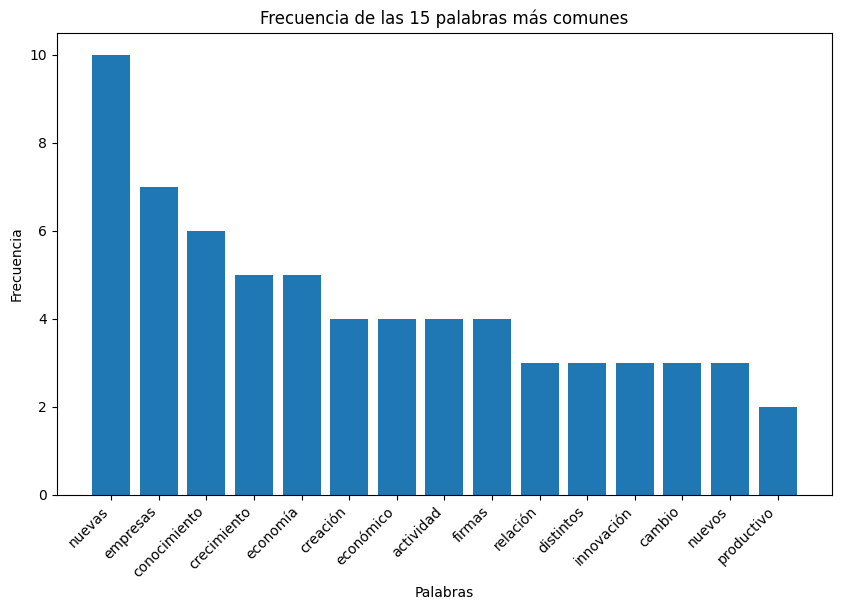

In [13]:
import matplotlib.pyplot as plt

palabras = [palabra for palabra, frecuencia in top_15]
frecuencias = [frecuencia for palabra, frecuencia in top_15]

plt.figure(figsize=(10, 6))
plt.bar(palabras, frecuencias)
plt.xlabel('Palabras')
plt.ylabel('Frecuencia')
plt.xticks(rotation=45, ha='right')
plt.title('Frecuencia de las 15 palabras más comunes')
plt.show()

In [14]:
texto_limpio = " ".join(tokens_limpios)

In [15]:
from wordcloud import WordCloud

nube = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(texto_limpio)

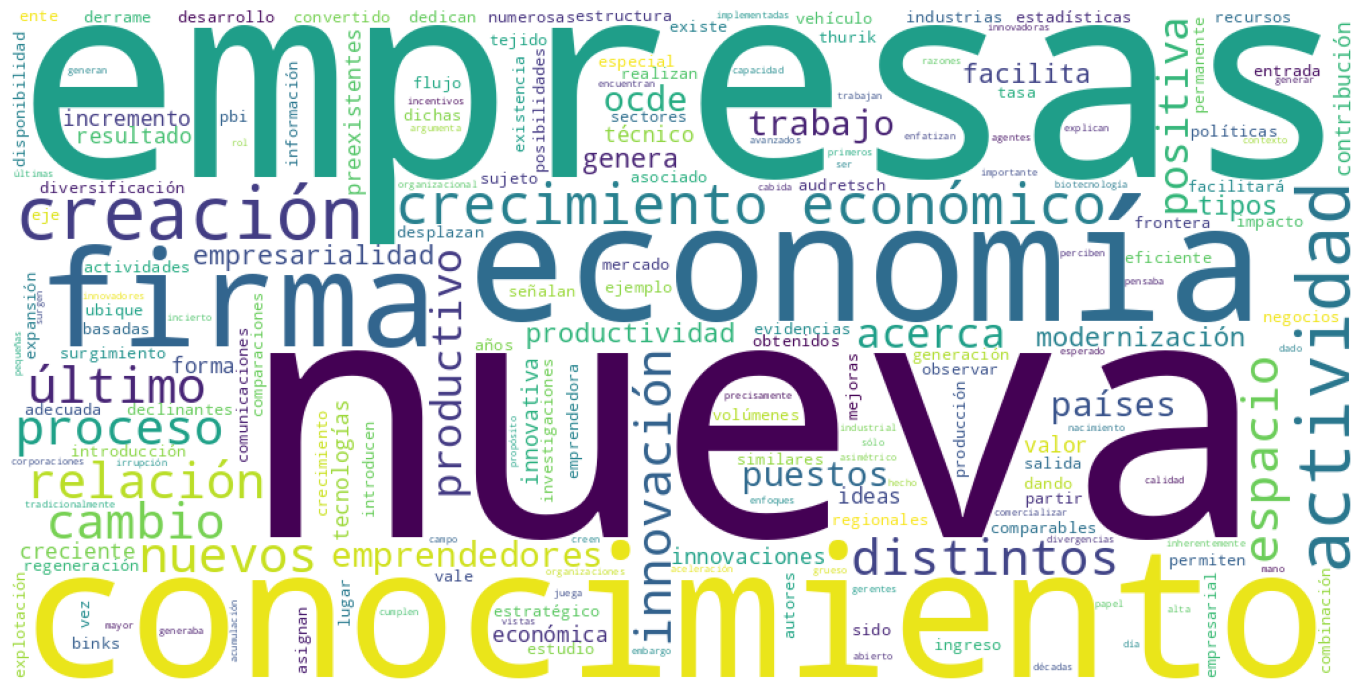

In [16]:
plt.figure(figsize=(15,7))

plt.imshow(nube)
plt.tight_layout(pad=0)
plt.axis('off')
plt.show()